In [1]:
import matplotlib.pyplot as plt

from baymorph import SyntheticSersic

In [2]:
galaxy = SyntheticSersic(
    flux=10000,
    re=10,
    n=4,
    q=0.7,
    theta=0.5,
    x0=50,
    y0=50,
)

image = galaxy.render(
    shape=(100, 100)
)

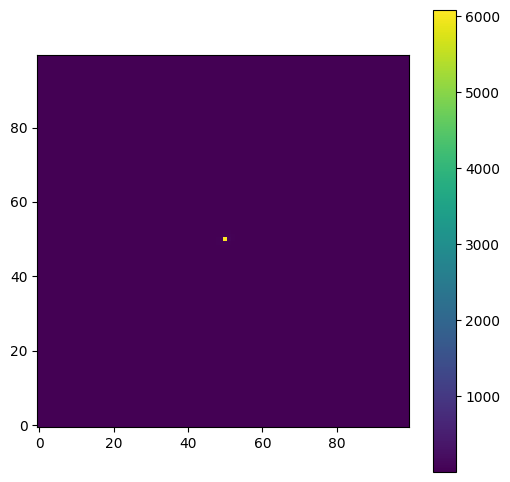

In [3]:
plt.figure(figsize=(6, 6))

plt.imshow(
    image,
    origin="lower",
)

plt.colorbar()

plt.show()

In [4]:
image.sum()

np.float64(9999.999999999996)

In [5]:
from baymorph import (
    DynestyFluxFitter,
    SersicModel,
    make_constant_noise_map,
)

In [6]:
true_flux = 1000.0

data = SersicModel(
    flux=true_flux,
    re=8.0,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(
    shape=(60, 60)
)

In [7]:
noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [8]:
def model_factory(flux):

    return SersicModel(
        flux=flux,
        re=8.0,
        n=2.0,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [9]:
fitter = DynestyFluxFitter(
    model_factory=model_factory,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
)

In [10]:
result = fitter.run(
    nlive=50
)

iter: 383 | +50 | bound: 5 | nc: 1 | ncall: 2641 | eff(%): 16.712 | loglstar:   -inf < -3308.179 <    inf | logz: -3312.886 +/-  0.287 | dlogz:  0.001 >  0.059                                       

In [11]:
result.flux_median

1001.1330780929915

In [12]:
print("True flux:", true_flux)
print("Recovered flux:", result.flux_median)

True flux: 1000.0
Recovered flux: 1001.1330780929915


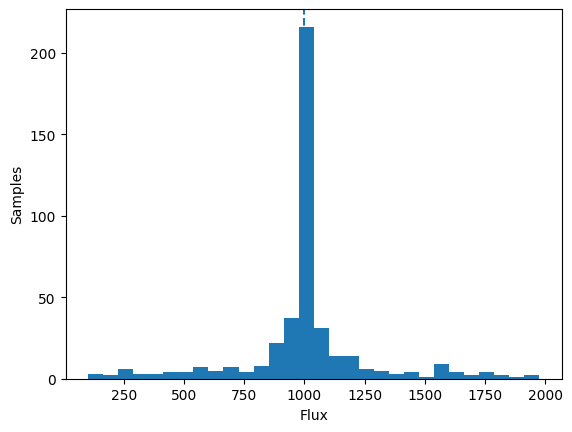

In [13]:
plt.hist(
    result.samples[:,0],
    bins=30,
)

plt.axvline(
    true_flux,
    linestyle="--",
)

plt.xlabel("Flux")
plt.ylabel("Samples")
plt.show()

In [14]:
from baymorph import DynestyFluxReFitter

In [15]:
true_flux = 1000.0
true_re = 8.0

data = SersicModel(
    flux=true_flux,
    re=true_re,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(shape=(60, 60))

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [16]:
def model_factory_flux_re(flux, re):
    return SersicModel(
        flux=flux,
        re=re,
        n=2.0,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [17]:
fitter = DynestyFluxReFitter(
    model_factory=model_factory_flux_re,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
    re_min=2.0,
    re_max=20.0,
)

result_2d = fitter.run(nlive=100)

iter: 949 | +100 | bound: 11 | nc: 1 | ncall: 4672 | eff(%): 22.944 | loglstar:   -inf < -3308.179 <    inf | logz: -3315.357 +/-  0.249 | dlogz:  0.001 >  0.109                                     

In [18]:
print("True flux:", true_flux)
print("Recovered flux:", result_2d.flux_median)

print("True Re:", true_re)
print("Recovered Re:", result_2d.re_median)

True flux: 1000.0
Recovered flux: 998.9129507065904
True Re: 8.0
Recovered Re: 7.9956942845737204


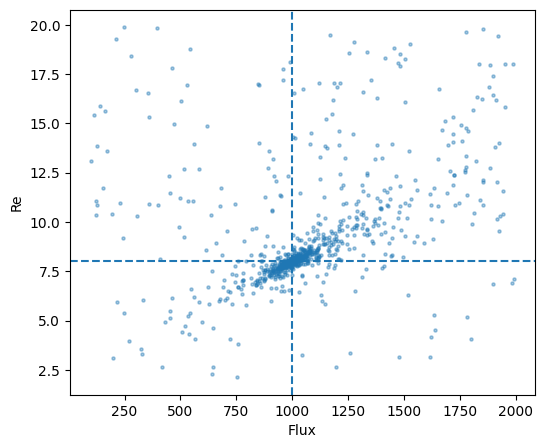

In [19]:
plt.figure(figsize=(6, 5))
plt.scatter(
    result_2d.samples[:, 0],
    result_2d.samples[:, 1],
    s=5,
    alpha=0.4,
)

plt.axvline(true_flux, linestyle="--")
plt.axhline(true_re, linestyle="--")

plt.xlabel("Flux")
plt.ylabel("Re")
plt.show()

In [20]:
from baymorph import plot_1d_posterior, plot_2d_samples

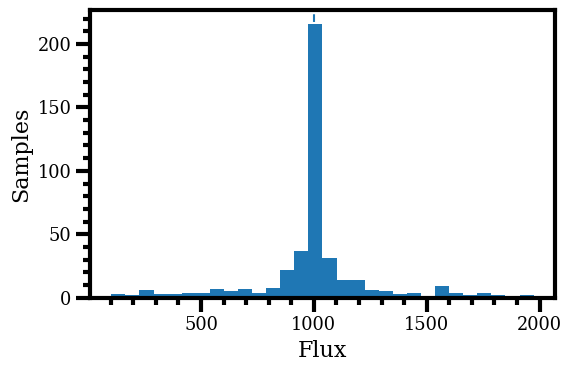

In [21]:
fig, ax = plot_1d_posterior(
    result.samples[:, 0],
    true_value=true_flux,
    parameter_name="Flux",
)

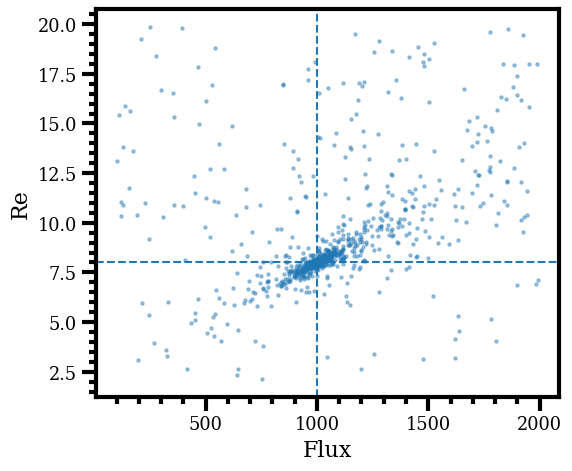

In [22]:
fig, ax = plot_2d_samples(
    result_2d.samples[:, 0],
    result_2d.samples[:, 1],
    true_x=true_flux,
    true_y=true_re,
    x_name="Flux",
    y_name="Re",
)

In [23]:
from baymorph import corner_plot

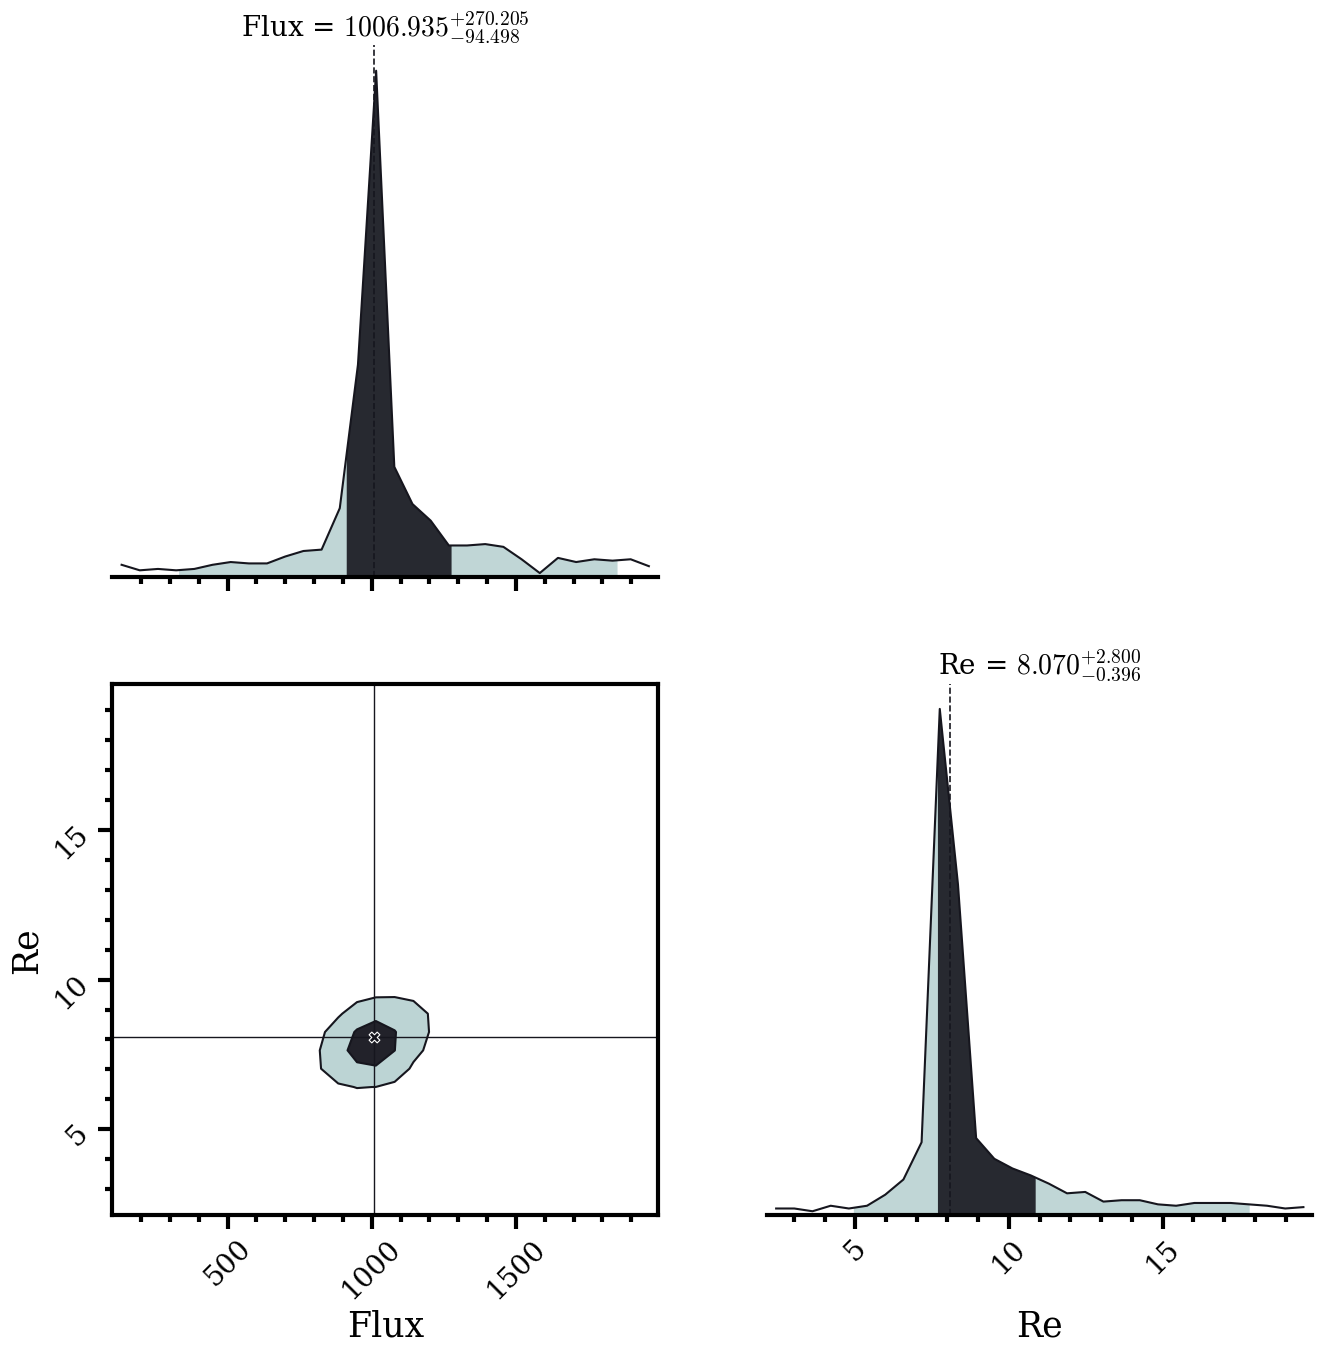

In [24]:
samples = result_2d.samples.T

fig, ax_grid, params = corner_plot(
    samples,
    parameter_labels=["Flux", "Re"],
    bins=30,
    write_medians=True,
)

In [25]:
best_model = SersicModel(
    flux=result_2d.flux_median,
    re=result_2d.re_median,
    n=2.0,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
)

model_image = best_model.render(
    shape=data.shape
)

(<Figure size 1800x600 with 6 Axes>,
 array([<Axes: title={'center': 'Data'}>,
        <Axes: title={'center': 'Model'}>,
        <Axes: title={'center': 'Residual'}>], dtype=object))

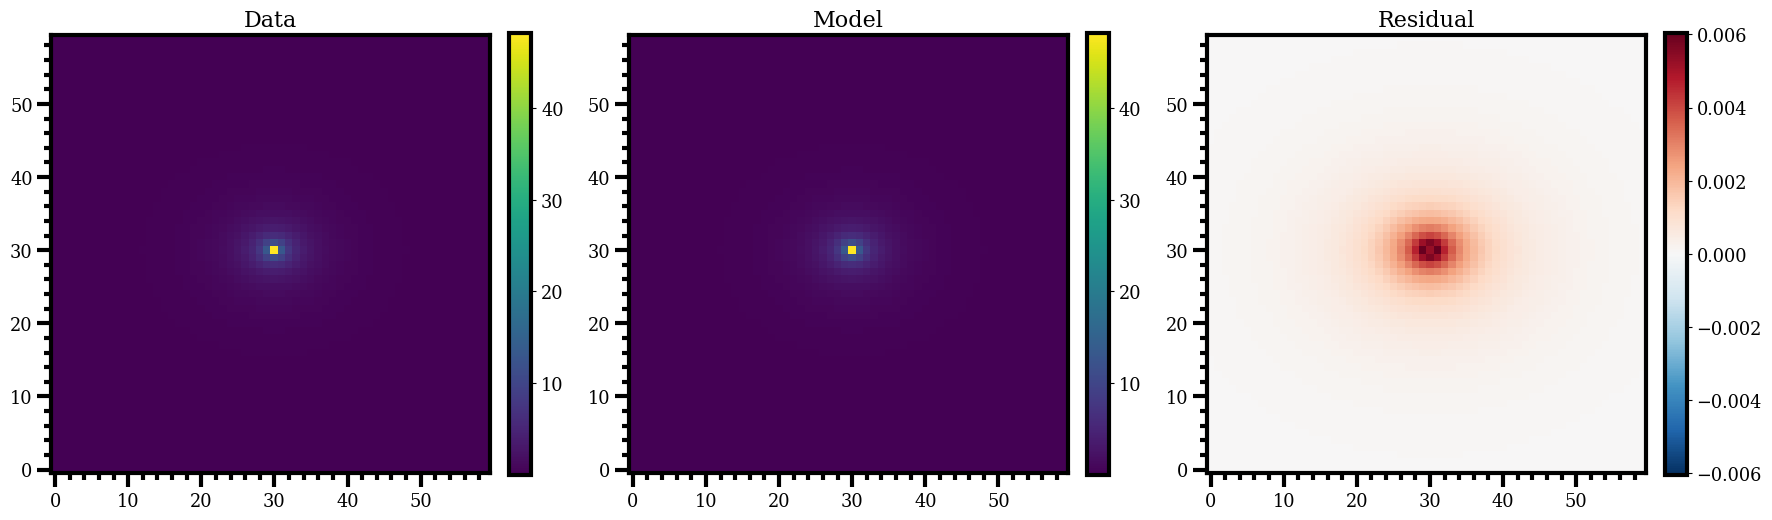

In [26]:
from baymorph import (
    plot_data_model_residual,
)

plot_data_model_residual(
    data,
    model_image,
)

In [27]:
from baymorph import DynestyFluxReNFitter

In [28]:
true_flux = 1000.0
true_re = 8.0
true_n = 2.0

data = SersicModel(
    flux=true_flux,
    re=true_re,
    n=true_n,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
).render(shape=(60, 60))

noise = make_constant_noise_map(
    data.shape,
    sigma=1.0,
)

In [29]:
def model_factory_flux_re_n(flux, re, n):
    return SersicModel(
        flux=flux,
        re=re,
        n=n,
        q=0.8,
        theta=0.0,
        x0=30.0,
        y0=30.0,
    )

In [30]:
fitter = DynestyFluxReNFitter(
    model_factory=model_factory_flux_re_n,
    data=data,
    noise=noise,
    flux_min=100.0,
    flux_max=2000.0,
    re_min=2.0,
    re_max=20.0,
    n_min=0.3,
    n_max=10.0,
)

result_3d = fitter.run(nlive=150)

iter: 2049 | +150 | bound: 29 | nc: 1 | ncall: 9745 | eff(%): 22.918 | loglstar:   -inf < -3308.183 <    inf | logz: -3319.899 +/-  0.264 | dlogz:  0.001 >  0.159                                    

In [31]:
print("True flux:", true_flux)
print("Recovered flux:", result_3d.flux_median)

print("True Re:", true_re)
print("Recovered Re:", result_3d.re_median)

print("True n:", true_n)
print("Recovered n:", result_3d.n_median)

True flux: 1000.0
Recovered flux: 1006.8741563693391
True Re: 8.0
Recovered Re: 8.055854745528533
True n: 2.0
Recovered n: 2.0038227264002213


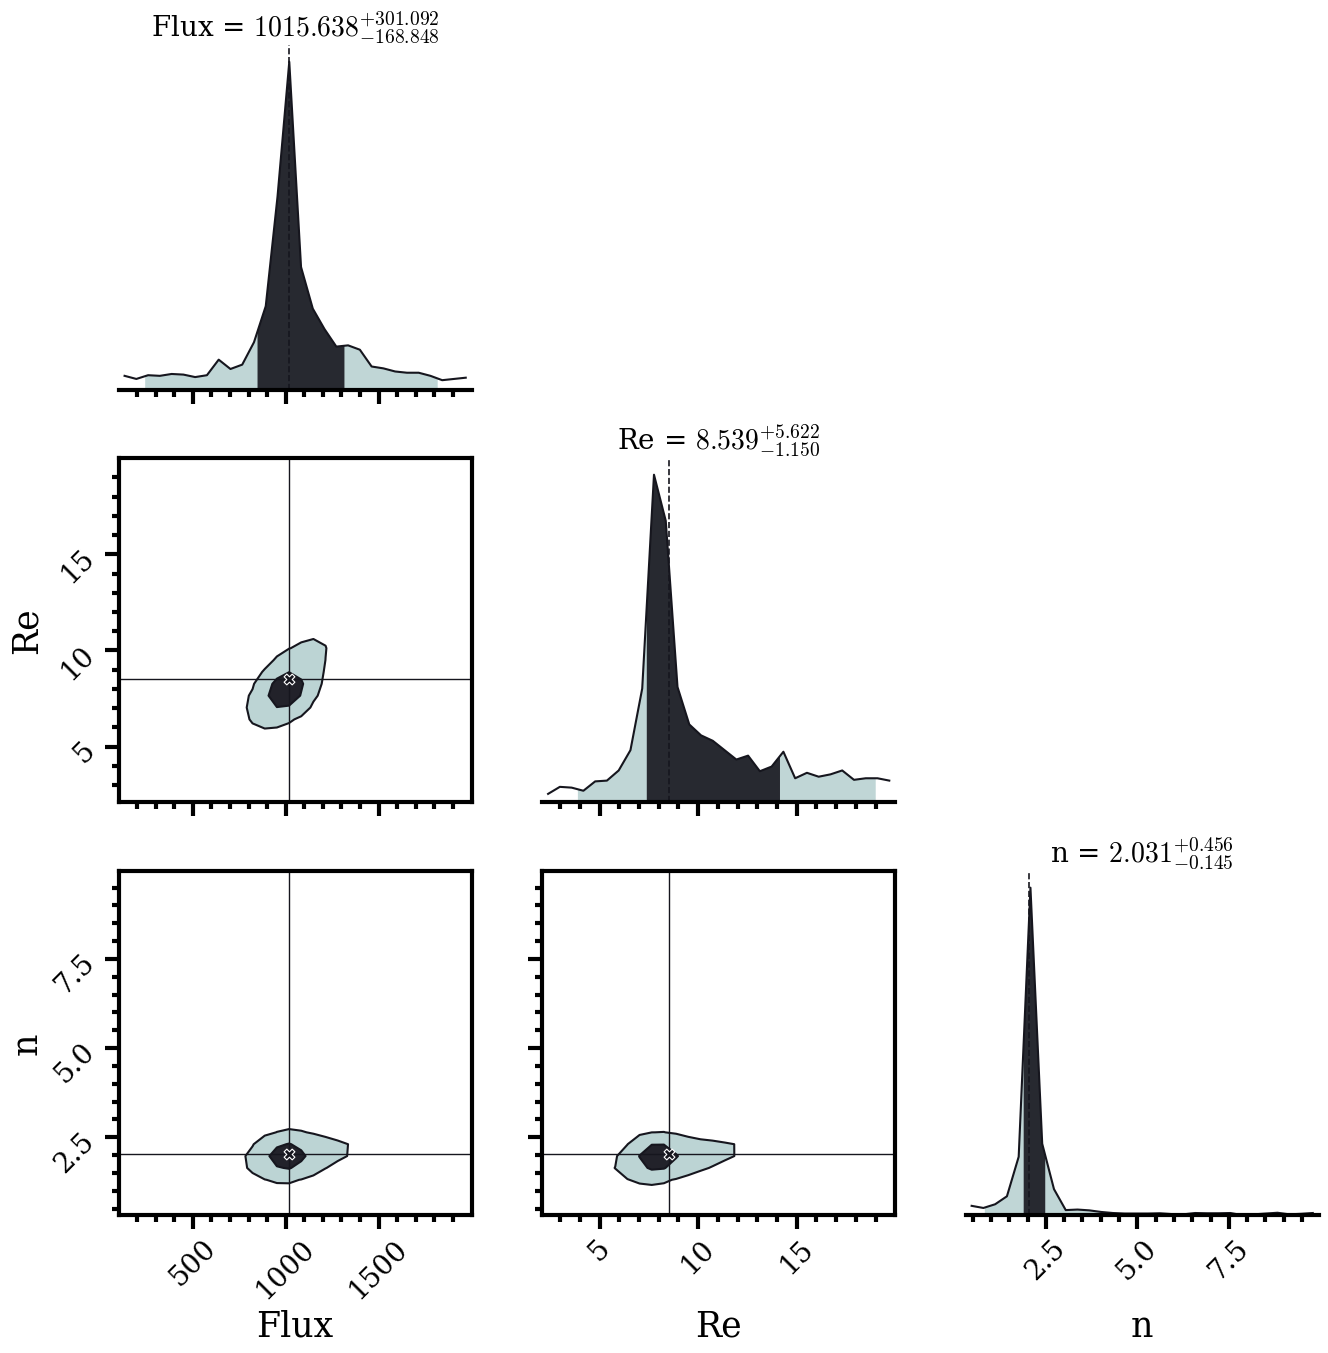

In [32]:
from baymorph import corner_plot

samples = result_3d.samples.T

fig, ax_grid, params = corner_plot(
    samples,
    parameter_labels=["Flux", "Re", "n"],
    bins=30,
    write_medians=True,
)

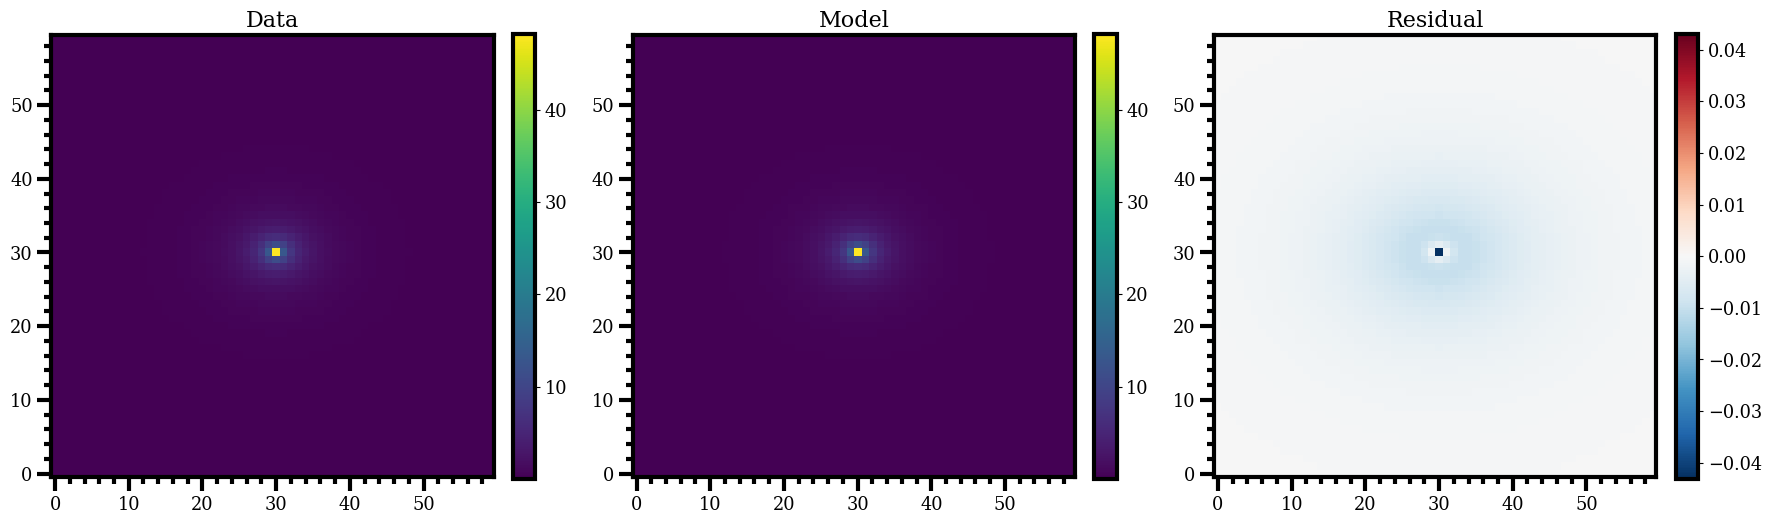

In [33]:
from baymorph import plot_data_model_residual

best_model = SersicModel(
    flux=result_3d.flux_median,
    re=result_3d.re_median,
    n=result_3d.n_median,
    q=0.8,
    theta=0.0,
    x0=30.0,
    y0=30.0,
)

model_image = best_model.render(
    shape=data.shape,
)

fig, axes = plot_data_model_residual(
    data,
    model_image,
)

In [36]:
result_3d.summary("flux"),result_3d.summary("re"),result_3d.summary("n")

({'q16': 967.1188282712823,
  'median': 1006.8741563693391,
  'q84': 1047.3558912618537},
 {'q16': 7.64608390107854,
  'median': 8.055854745528533,
  'q84': 8.563052333256627},
 {'q16': 1.962615457078441,
  'median': 2.0038227264002213,
  'q84': 2.05499114597872})

In [37]:
result_3d.flux_median, result_3d.re_median, result_3d.n_median

(1006.8741563693391, 8.055854745528533, 2.0038227264002213)

In [38]:
result_3d.posterior_samples.shape

(2199, 3)

(<Figure size 1500x1500 with 9 Axes>,
 array([[<Axes: >, <Axes: >, <Axes: >],
        [<Axes: ylabel='par2'>, <Axes: >, <Axes: >],
        [<Axes: xlabel='par1', ylabel='par3'>, <Axes: xlabel='par2'>,
         <Axes: xlabel='par3'>]], dtype=object),
 array([[[ 955.01626545,  971.65900257, 1000.06904457, ...,
           969.58966343, 1027.85052145, 1015.89106906],
         [   7.68619641,    7.60832232,    7.90253845, ...,
             7.95279911,    8.5643092 ,    8.39567292],
         [   1.97991859,    1.96001354,    1.98416752, ...,
             2.02757461,    2.05124601,    2.04051702]]],
       shape=(1, 3, 2199)))

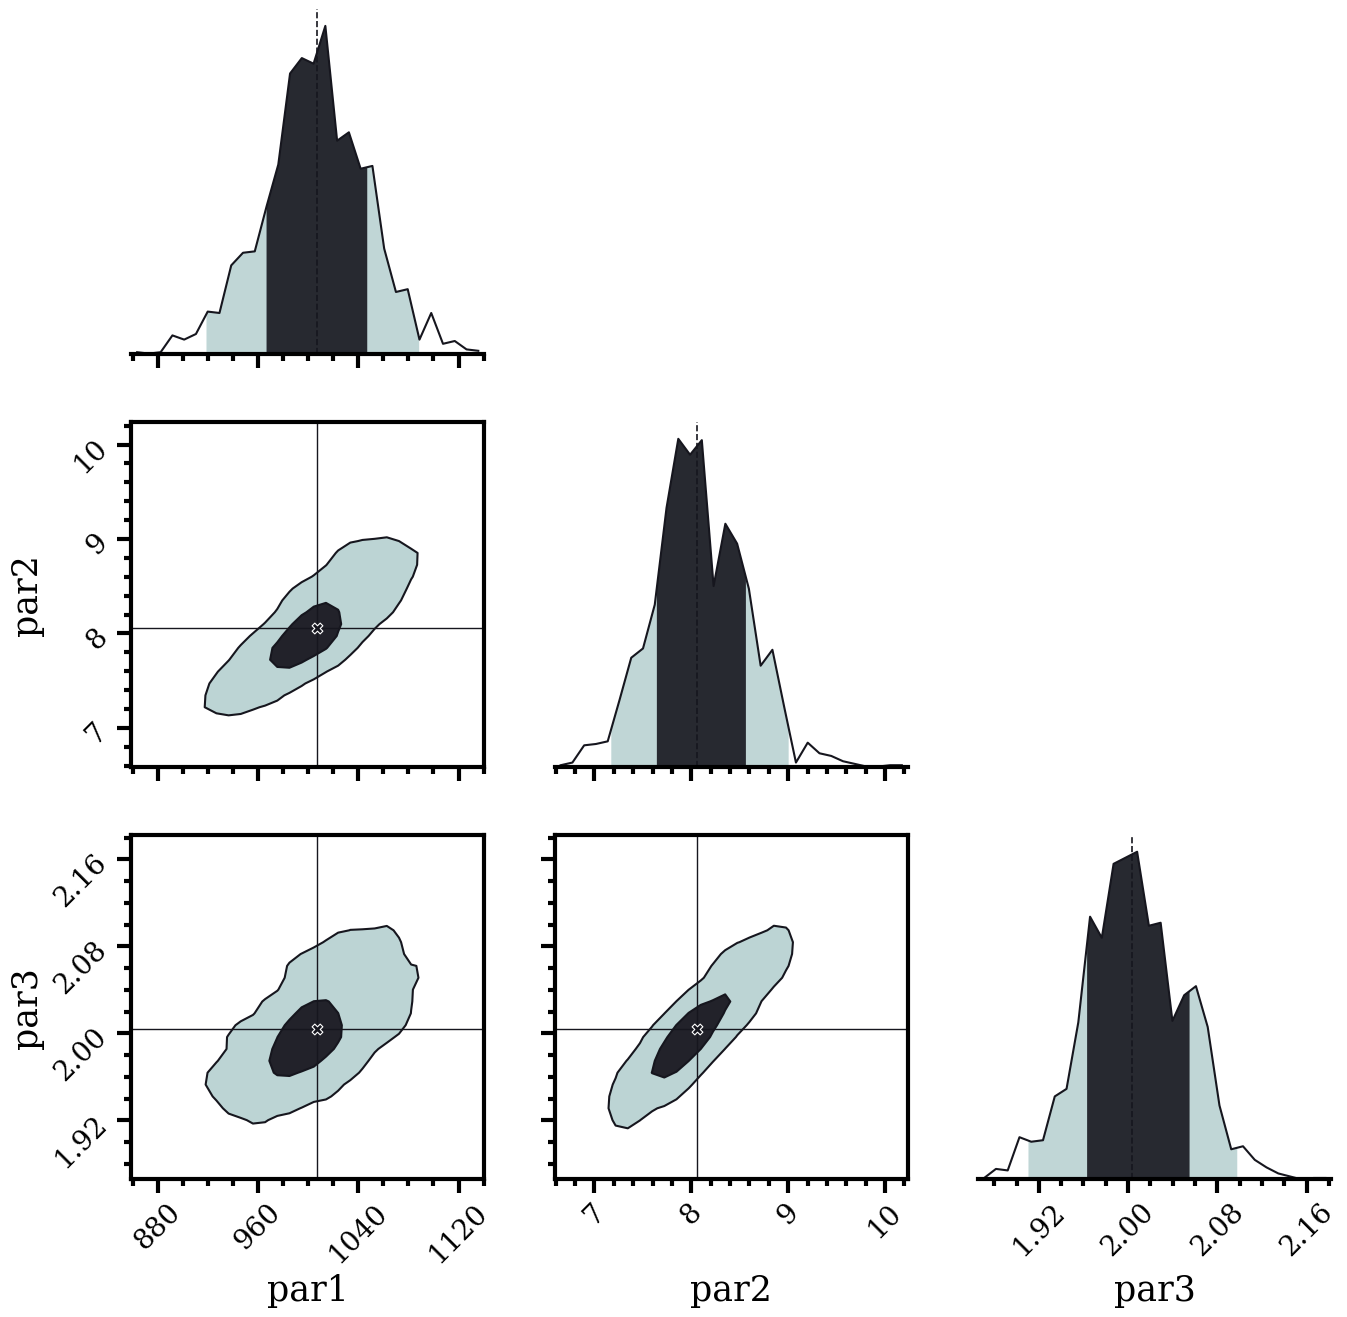

In [39]:
corner_plot(
    result_3d.posterior_samples.T
)

In [41]:
import numpy as np

np.cov(
    result_3d.posterior_samples.T
)

array([[1.71320700e+03, 1.71919077e+01, 1.31296483e+00],
       [1.71919077e+01, 2.26356127e-01, 2.02115483e-02],
       [1.31296483e+00, 2.02115483e-02, 2.06551427e-03]])